# Demo Instance Segmentation
YOLO11n-seg · YOLOv8n-seg · Mask R-CNN

## 1. Model terbaik
Sumber: output final 18 evaluasi pada cell 156 notebook `VISKOM_Instance_Segmentation.ipynb` (RETEST40). Test asli: 359 gambar; test mandiri: 40 gambar. Angka cadangan disalin sesuai presisi tampilan (4 desimal).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

columns = ['model','input_size','test_set','mask_mAP50','mask_mAP50_95']
df = pd.DataFrame([('Mask R-CNN', 320, 'custom', 0.1044, 0.0686), ('Mask R-CNN', 320, 'original', 0.0978, 0.052), ('Mask R-CNN', 640, 'custom', 0.1027, 0.0667), ('Mask R-CNN', 640, 'original', 0.1047, 0.0592), ('Mask R-CNN', 960, 'custom', 0.0889, 0.0615), ('Mask R-CNN', 960, 'original', 0.0896, 0.0514), ('YOLO11n-seg', 320, 'custom', 0.1279, 0.0678), ('YOLO11n-seg', 320, 'original', 0.1161, 0.0649), ('YOLO11n-seg', 640, 'custom', 0.1048, 0.0571), ('YOLO11n-seg', 640, 'original', 0.164, 0.1057), ('YOLO11n-seg', 960, 'custom', 0.0838, 0.0531), ('YOLO11n-seg', 960, 'original', 0.1456, 0.0898), ('YOLOv8n-seg', 320, 'custom', 0.1019, 0.0559), ('YOLOv8n-seg', 320, 'original', 0.1028, 0.0562), ('YOLOv8n-seg', 640, 'custom', 0.1334, 0.0748), ('YOLOv8n-seg', 640, 'original', 0.1342, 0.0823), ('YOLOv8n-seg', 960, 'custom', 0.1012, 0.0643), ('YOLOv8n-seg', 960, 'original', 0.1192, 0.0719)], columns=columns)
assert len(df) == 18 and not df.duplicated(columns[:3]).any()
metric = 'mask_mAP50_95'
print('Model terbaik pada masing-masing test set:')
display(df.loc[df.groupby('test_set')[metric].idxmax()].round(4).reset_index(drop=True))
print('Model terbaik per arsitektur pada test asli:')
best_original = df[df.test_set == 'original'].sort_values(metric, ascending=False).drop_duplicates('model')
display(best_original.reset_index(drop=True))

Model terbaik pada masing-masing test set:


,model,input_size,test_set,mask_mAP50,mask_mAP50_95
0,YOLOv8n-seg,640,custom,0.1334,0.0748
1,YOLO11n-seg,640,original,0.1640,0.1057


Model terbaik per arsitektur pada test asli:


,model,input_size,test_set,mask_mAP50,mask_mAP50_95
0,YOLO11n-seg,640,original,0.1640,0.1057
1,YOLOv8n-seg,640,original,0.1342,0.0823
2,Mask R-CNN,640,original,0.1047,0.0592


## 2. Perbandingan seluruh eksperimen NRP
Tiga arsitektur × tiga ukuran input (320, 640, 960) × dua test set. Grafik menampilkan semua 18 hasil untuk setiap metrik. Mask mAP50–95 menjadi metrik utama; semakin tinggi semakin baik.

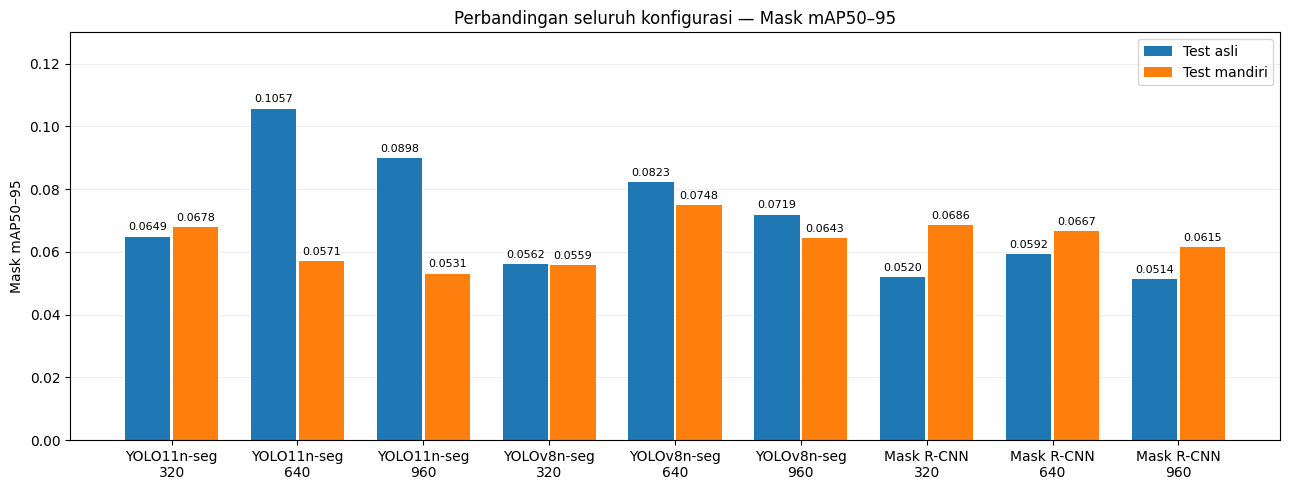

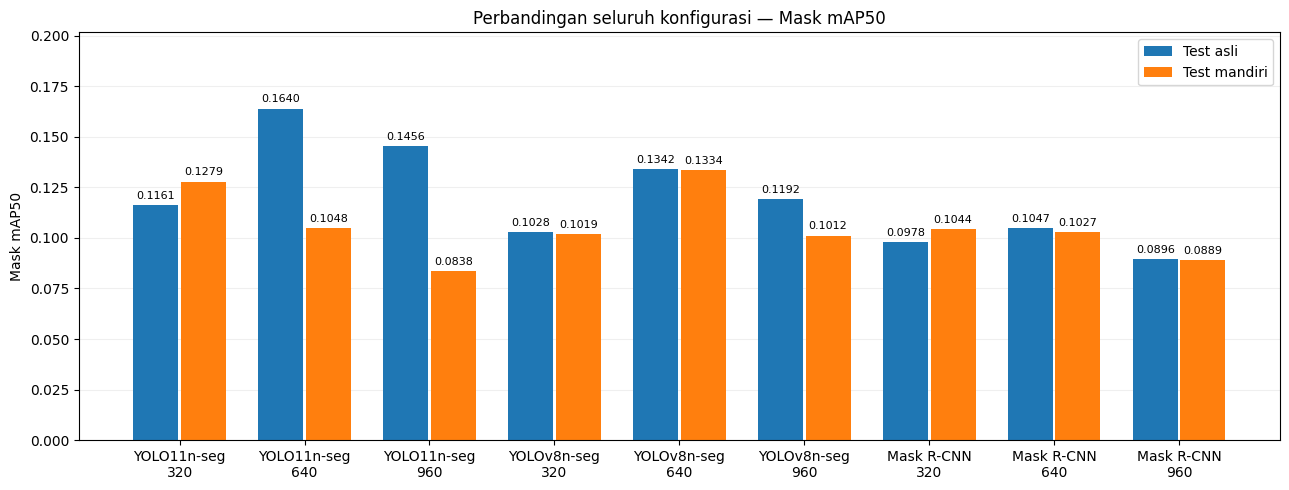

,model,input_size,test_set,mask_mAP50,mask_mAP50_95
0,YOLOv8n-seg,640,custom,0.1334,0.0748
1,Mask R-CNN,320,custom,0.1044,0.0686
2,YOLO11n-seg,320,custom,0.1279,0.0678
3,Mask R-CNN,640,custom,0.1027,0.0667
4,YOLOv8n-seg,960,custom,0.1012,0.0643
5,Mask R-CNN,960,custom,0.0889,0.0615
6,YOLO11n-seg,640,custom,0.1048,0.0571
7,YOLOv8n-seg,320,custom,0.1019,0.0559
8,YOLO11n-seg,960,custom,0.0838,0.0531
9,YOLO11n-seg,640,original,0.1640,0.1057


In [ ]:
models = ['YOLO11n-seg', 'YOLOv8n-seg', 'Mask R-CNN']
sizes = [320, 640, 960]
order = pd.MultiIndex.from_product([models, sizes], names=['model','input_size'])
for metric, title in [('mask_mAP50_95', 'Mask mAP50–95'), ('mask_mAP50', 'Mask mAP50')]:
    p = df.pivot(index=['model','input_size'], columns='test_set', values=metric).reindex(order)
    x = np.arange(len(p))
    fig, ax = plt.subplots(figsize=(13, 5))
    for offset, split, label in [(-0.19,'original','Test asli'), (0.19,'custom','Test mandiri')]:
        bars = ax.bar(x + offset, p[split], width=0.36, label=label)
        ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    ax.set_xticks(x, [f'{m}\n{s}' for m,s in p.index])
    ax.set_ylim(0, p.max().max()*1.23)
    ax.set_ylabel(title)
    ax.set_title(f'Perbandingan seluruh konfigurasi — {title}')
    ax.legend(); ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()
display(df.sort_values(['test_set','mask_mAP50_95'], ascending=[True,False]).reset_index(drop=True))

## 3. Demo gambar baru


### 3.1 Setup Colab dan checkpoint

In [ ]:
%pip install -q ultralytics
from google.colab import drive, files
import torch
import torch.nn.functional as NF
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from ultralytics import YOLO
from PIL import Image, ImageOps
import cv2, io, json

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/CPMK3')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SELECTION_SPLIT = 'original' # original atau custom
CONF = 0.25
selected = df[df.test_set == SELECTION_SPLIT].sort_values('mask_mAP50_95', ascending=False).drop_duplicates('model').set_index('model').reindex(models)
SIZES = selected.input_size.astype(int).to_dict()
paths = {'YOLO11n-seg': ROOT / f"results/YOLO11n_{SIZES['YOLO11n-seg']}/weights/best.pt",
         'YOLOv8n-seg': ROOT / f"results/YOLOv8n_{SIZES['YOLOv8n-seg']}/weights/best.pt",
         'Mask R-CNN': ROOT / f"results/MaskRCNN_{SIZES['Mask R-CNN']}/last.pth"}
missing = [str(p) for p in paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError('Checkpoint tidak ditemukan:\n' + '\n'.join(missing))
print('Device:', DEVICE)
print(SIZES)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Device: cpu
{'YOLO11n-seg': 640, 'YOLOv8n-seg': 640, 'Mask R-CNN': 640}


### 3.2 Load tiga model

In [ ]:
yolo11 = YOLO(str(paths['YOLO11n-seg']))
yolov8 = YOLO(str(paths['YOLOv8n-seg']))
size = SIZES['Mask R-CNN']
ckpt = torch.load(paths['Mask R-CNN'], map_location='cpu', weights_only=True)
mask_model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=size, max_size=size)
mask_model.roi_heads.box_predictor = FastRCNNPredictor(mask_model.roi_heads.box_predictor.cls_score.in_features, ckpt['num_classes'])
mask_model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_model.roi_heads.mask_predictor.conv5_mask.in_channels, 256, ckpt['num_classes'])
mask_model.load_state_dict(ckpt['model_state_dict'])
mask_model.to(DEVICE).eval()
mask_model.roi_heads.score_thresh = CONF
COCO_TRAIN_JSON = Path('/content/panoptic-indoor-coco/train/_annotations.coco.json')
mask_names = {}
if COCO_TRAIN_JSON.is_file():
    categories = {int(x['id']): x['name'] for x in json.loads(COCO_TRAIN_JSON.read_text())['categories']}
    mask_names = {int(v): categories[int(k)] for k,v in ckpt['category_mapping'].items()}
else:
    print('JSON COCO tidak tersedia: nama kelas Mask R-CNN ditampilkan sebagai ID label.')
print('Ketiga model berhasil dimuat.')

JSON COCO tidak tersedia: nama kelas Mask R-CNN ditampilkan sebagai ID label.
Ketiga model berhasil dimuat.


### 3.3 Upload satu gambar dan tampilkan hasil
Jalankan ulang cell ini untuk mencoba gambar lain. Hasil: gambar asli dan tiga visualisasi instance segmentation berdampingan. Mask R-CNN menggunakan resize + padding sesuai notebook training, lalu mask dipetakan kembali ke ukuran asli.

Saving WhatsApp Image 2026-11-25 at 14.19.17.jpeg to WhatsApp Image 2026-11-25 at 14.19.17.jpeg


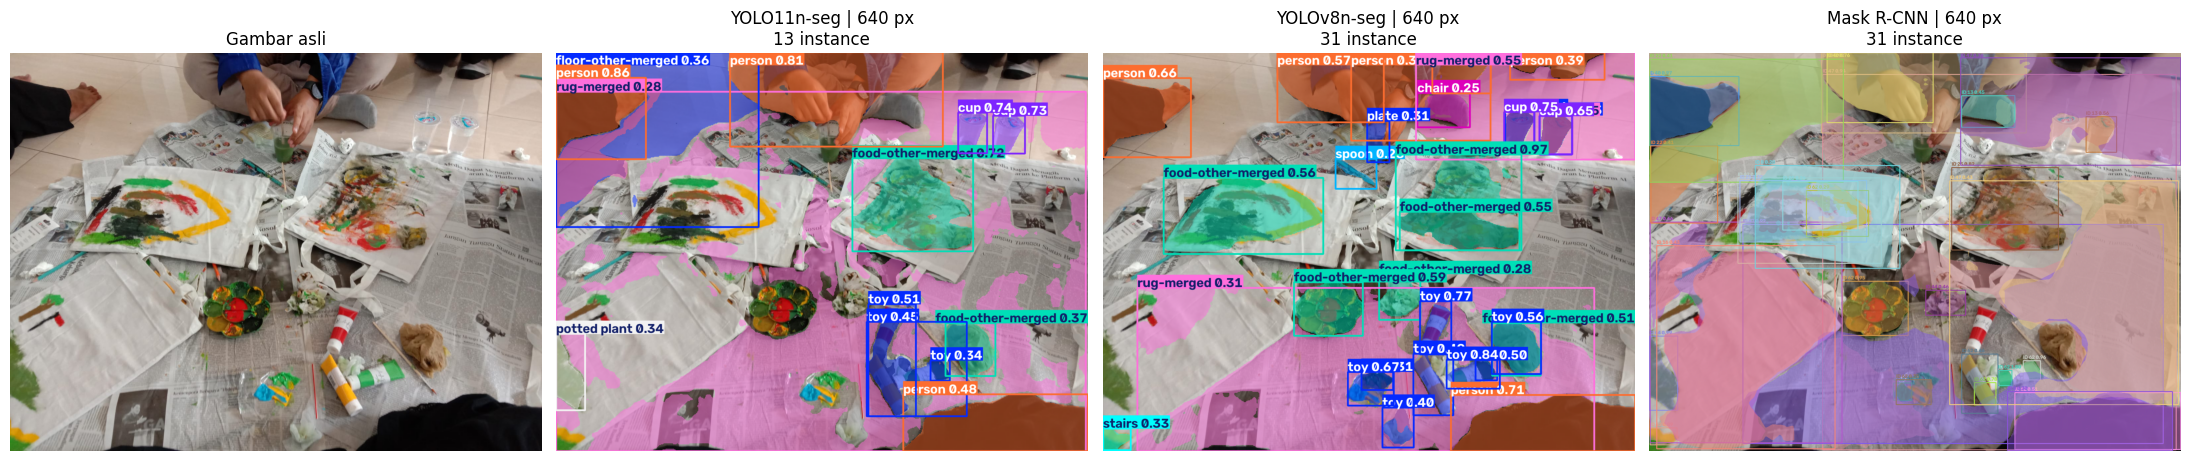

In [ ]:
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('Upload tepat satu gambar.')
name, content = next(iter(uploaded.items()))
image = ImageOps.exif_transpose(Image.open(io.BytesIO(content))).convert('RGB')
rgb = np.array(image)
h, w = rgb.shape[:2]

def render_yolo(model, size):
    result = model.predict(source=image, imgsz=size, conf=CONF, device=0 if DEVICE.type == 'cuda' else 'cpu', verbose=False)[0]
    return cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB), len(result.boxes)

def render_maskrcnn():
    size = SIZES['Mask R-CNN']
    scale = size / max(h, w)
    nh, nw = max(1, round(h*scale)), max(1, round(w*scale))
    left, top = (size-nw)//2, (size-nh)//2
    tensor = NF.interpolate(to_tensor(image)[None], size=(nh,nw), mode='bilinear', align_corners=False)[0]
    tensor = NF.pad(tensor, (left,size-nw-left,top,size-nh-top))
    with torch.inference_mode():
        out = mask_model([tensor.to(DEVICE)])[0]
    canvas = rgb.copy()
    rng = np.random.default_rng(42)
    count = 0
    for score, label, mask in zip(out['scores'].cpu(), out['labels'].cpu(), out['masks'].cpu()):
        if float(score) < CONF: continue
        prob = mask[0,top:top+nh,left:left+nw].numpy()
        binary = cv2.resize(prob,(w,h),interpolation=cv2.INTER_LINEAR) >= .5
        if not binary.any(): continue
        color = rng.integers(50,256,3).tolist()
        canvas[binary] = (canvas[binary]*.55 + np.array(color)*.45).astype(np.uint8)
        ys,xs = np.where(binary)
        x1,y1,x2,y2 = int(xs.min()),int(ys.min()),int(xs.max()),int(ys.max())
        cv2.rectangle(canvas,(x1,y1),(x2,y2),color,2)
        label_text = mask_names.get(int(label),f'ID {int(label)}')
        cv2.putText(canvas,f'{label_text} {float(score):.2f}',(x1,max(15,y1-5)),cv2.FONT_HERSHEY_SIMPLEX,.5,color,2,cv2.LINE_AA)
        count += 1
    return canvas, count

views = [render_yolo(yolo11,SIZES['YOLO11n-seg']), render_yolo(yolov8,SIZES['YOLOv8n-seg']), render_maskrcnn()]
fig, axes = plt.subplots(1,4,figsize=(22,7))
axes[0].imshow(rgb); axes[0].set_title('Gambar asli')
for ax, model_name, (visual,count) in zip(axes[1:],models,views):
    ax.imshow(visual); ax.set_title(f'{model_name} | {SIZES[model_name]} px\n{count} instance')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()